# 2.03 · Probability distributions: describing numbers you cannot predict exactly

Notebook 2.01 · Basics showed that the measurement noise is random, that the parameters are fixed but unknown to
us, and that imperfect physics adds a model error. All of these are described with the same tool: a
**probability distribution**, which says which values a quantity is likely to take and which it is not. This
notebook builds the vocabulary that every later notebook uses, with GPS noise as the running example.

**Words this notebook defines:** random variable, probability density (pdf), cumulative distribution (cdf),
expectation (mean), variance, standard deviation, quantile, median, mode, Gaussian, uniform, exponential, Laplace,
Student-t, Cauchy, heavy tails, chi-square, χ²/N, multivariate Gaussian, covariance matrix, correlation,
Mahalanobis distance, Cholesky factor, log-normal.

**Before this:** [2.01](2-01_basics.ipynb). · **You will be able to:** read a pdf and a cdf; compute and interpret mean, median, mode,
variance and quantiles; recognise heavy tails; use χ²/N to check a noise level; read a covariance matrix as an
ellipse. · **Optional sections:** 6 (log-normal) on a first reading. Sections 5-6 use matrices; 2.06 is the primer.

**Problems in this notebook**

| example | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| daily GPS position noise (sections 1-3) | 1 noise value per day | 10,000 simulated days | none (noise only) | – |
| a set of fit residuals (section 4) | – | 57 residuals (19 sites × 3 components) | none | – |
| east and north noise of one site (section 5) | 2 | simulated pairs | none | – |
| a viscosity known within a factor (section 6) | 1 | – | none | – |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

import bayeskit as bk
from bayeskit import plotting as BP, style as S

rng = np.random.default_rng(1)
C1, C2, C3, C4 = S.BLUE, S.ORANGE, S.AQUA, S.VIOLET        # categorical colours for several curves at once

## 1. A random variable and its distribution

**In plain words.** Measure the east position of a GPS antenna every day and subtract the true position. The
leftover changes from day to day: that leftover is a *random variable*. Nobody can say what tomorrow's value will
be, but after many days you can say how often each value occurs. That description is the *distribution*. The
**probability density** (pdf) is how crowded the values are near each number, and the **cumulative distribution**
(cdf) is the share of values below each number.

**Precisely.** A continuous random variable $X$ has a density $p(x) \ge 0$ with $\int p(x)\,dx = 1$. Probabilities
are areas under it, $P(a \le X \le b) = \int_a^b p(x)\,dx$, and the cdf is $F(x) = P(X \le x)$. The Gaussian
(normal) density with mean $\mu$ and standard deviation $\sigma$ is

$$p(x) = \frac{1}{\sigma\sqrt{2\pi}}\exp\!\left[-\frac{(x-\mu)^2}{2\sigma^2}\right], \qquad X \sim N(\mu, \sigma^2).$$

Note that $p(x)$ itself is not a probability: it has units of 1/mm, and only areas under it are probabilities.

saved figures/2-03_pdf_cdf.png


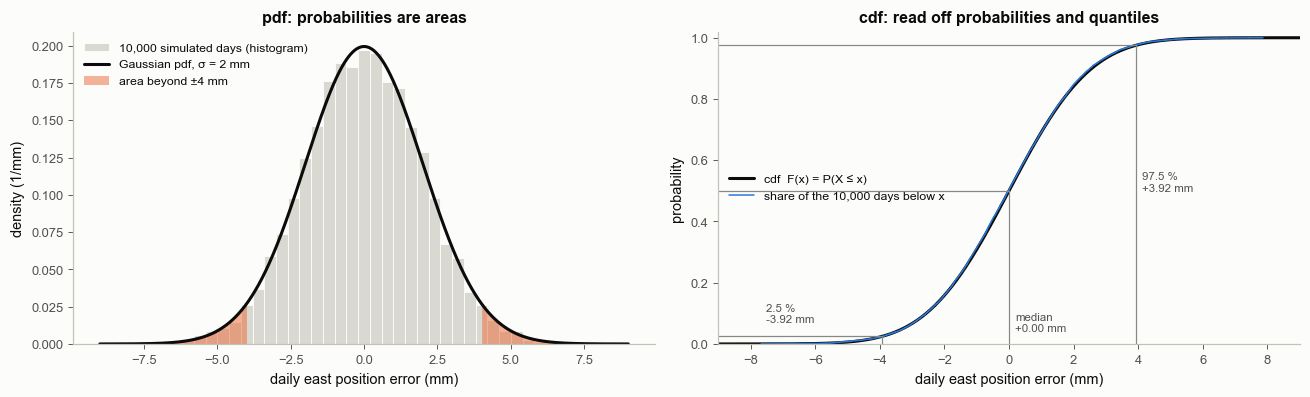

In [2]:
SIG = 2.0                                                    # daily GPS noise, mm
x = np.linspace(-9, 9, 1201)
draws = SIG * rng.standard_normal(10_000)
gauss = stats.norm(0, SIG)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.7))
ax = axs[0]
ax.hist(draws, bins=np.arange(-9, 9.01, 0.4), density=True, color="#d9d8d1", edgecolor=S.SURFACE, lw=0.6,
        label="10,000 simulated days (histogram)")
ax.plot(x, gauss.pdf(x), color=S.INK, lw=2, label="Gaussian pdf, σ = 2 mm")
tail = np.abs(x) >= 4
ax.fill_between(x, gauss.pdf(x), where=x >= 4, color=C2, alpha=0.5, lw=0)
ax.fill_between(x, gauss.pdf(x), where=x <= -4, color=C2, alpha=0.5, lw=0, label="area beyond ±4 mm")
ax.set_xlabel("daily east position error (mm)"); ax.set_ylabel("density (1/mm)")
ax.set_title("pdf: probabilities are areas")
ax.legend(fontsize=8, loc="upper left")
ax = axs[1]
ax.plot(x, gauss.cdf(x), color=S.INK, lw=2, label="cdf  F(x) = P(X ≤ x)")
xs = np.sort(draws)
ax.step(xs, np.arange(1, xs.size + 1) / xs.size, color=C1, lw=1, where="post", label="share of the 10,000 days below x")
for q, lab in [(0.025, "2.5 %"), (0.5, "median"), (0.975, "97.5 %")]:
    xq = gauss.ppf(q)
    ax.plot([xq, xq], [0, q], color=S.MUTED, lw=0.8)
    ax.plot([-9, xq], [q, q], color=S.MUTED, lw=0.8)
    tx, ty = {0.025: (xq - 3.6, 0.07), 0.5: (xq + 0.2, 0.04), 0.975: (xq + 0.2, 0.5)}[q]
    ax.text(tx, ty, f"{lab}\n{xq:+.2f} mm", fontsize=7.5, color=S.INK2)
ax.set_xlim(-9, 9); ax.set_ylim(0, 1.02)
ax.set_xlabel("daily east position error (mm)"); ax.set_ylabel("probability")
ax.set_title("cdf: read off probabilities and quantiles")
ax.legend(fontsize=8, loc="center left")
fig.tight_layout()
bk.savefig(fig, "2-03_pdf_cdf")
plt.show()

**How to read it.** Left: the histogram of simulated days follows the pdf; the orange area is the probability of an
error larger than 4 mm in either direction. Right: the cdf rises from 0 to 1; the staircase is the same quantity
counted from the simulated days. A *quantile* is read backwards from the cdf: the 97.5 % quantile is the value below
which 97.5 % of the days fall.

**Worked example.** What is the chance that one day's error exceeds 4 mm in size, if $\sigma$ = 2 mm?
1. Standardise: $z = 4 / \sigma$.
2. One tail: $1 - F_{N(0,1)}(z)$; both tails: twice that (the Gaussian is symmetric).
3. Check by counting the simulated days.

In [3]:
z = 4.0 / SIG
one_tail = 1 - stats.norm.cdf(z)
print(f"step 1: z = 4 mm / {SIG} mm = {z:.2f}")
print(f"step 2: one tail 1 - F(z) = {one_tail:.5f};  both tails = {2 * one_tail:.5f}")
print(f"step 3: share of the 10,000 simulated days with |error| > 4 mm = {np.mean(np.abs(draws) > 4):.5f}")
print(f"        expected scatter of that count-based share: ±{np.sqrt(2 * one_tail * (1 - 2 * one_tail) / draws.size):.5f} (1 sd)")
print(f"in words: one day in {1 / (2 * one_tail):.0f}; in a 10-year daily series (3652 days) about {3652 * 2 * one_tail:.0f} days")

step 1: z = 4 mm / 2.0 mm = 2.00
step 2: one tail 1 - F(z) = 0.02275;  both tails = 0.04550
step 3: share of the 10,000 simulated days with |error| > 4 mm = 0.04380
        expected scatter of that count-based share: ±0.00208 (1 sd)
in words: one day in 22; in a 10-year daily series (3652 days) about 166 days


**Common misreadings.**
* "The pdf value at 0 is the probability of exactly 0." No: for a continuous quantity the probability of any exact
  value is zero; only intervals have probability.
* "Beyond 2σ never happens." It happens regularly: the last printed line gives how often, and how many days of a
  10-year daily series that is.

**In geodesy.** The σ you give each GPS component is a statement about this distribution. Choosing it too small or
too large changes every downstream answer (section 4).

## 2. Expectation, variance, standard deviation, quantiles

**In plain words.** The **expectation** (mean) is the average over very many repeats, the balance point of the
pdf. The **variance** is the average squared distance from the mean, and its square root, the **standard
deviation**, is the typical size of a deviation. For a symmetric bell curve the mean, the median (half above, half
below) and the mode (the peak) coincide. For a skewed distribution they do not, and which one you quote matters.

**Precisely.**
$$\mathbb E[X] = \int x\,p(x)\,dx, \qquad \mathrm{Var}[X] = \mathbb E\big[(X - \mathbb E X)^2\big], \qquad \mathrm{sd} = \sqrt{\mathrm{Var}}.$$
For $N(\mu, \sigma^2)$: mean $\mu$, sd $\sigma$, and the probability within $\pm1, \pm2, \pm3\sigma$ is the area
shaded below. For the exponential distribution (waiting times of a memoryless process, in which the chance of an
event does not depend on how long ago the last one was; rate $r$) the mean is $1/r$ but the median is $\ln 2 / r$.
A distribution is **skewed** when it is lopsided, with a longer tail on one side.

saved figures/2-03_mean_sd_quantiles.png


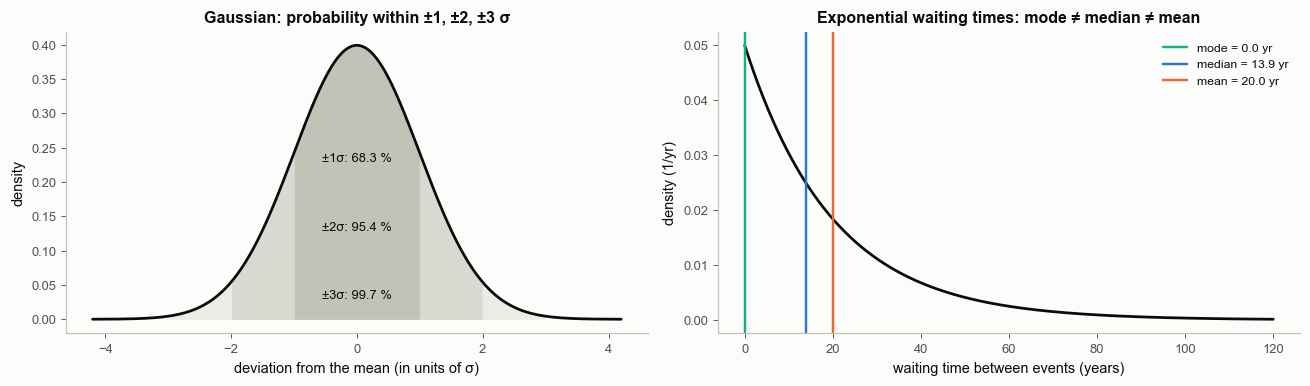

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axs[0]
xx = np.linspace(-4.2, 4.2, 800)
pdf = stats.norm.pdf(xx)
for k, shade in zip([3, 2, 1], ["#ecebe6", "#d9d8d1", "#c3c2b7"]):
    m = np.abs(xx) <= k
    ax.fill_between(xx[m], pdf[m], color=shade, lw=0)
    frac = stats.norm.cdf(k) - stats.norm.cdf(-k)
    ax.text(0, 0.03 + 0.1 * (3 - k), f"±{k}σ: {100 * frac:.1f} %", ha="center", fontsize=8.5, color=S.INK)
ax.plot(xx, pdf, color=S.INK, lw=1.8)
ax.set_xlabel("deviation from the mean (in units of σ)"); ax.set_ylabel("density")
ax.set_title("Gaussian: probability within ±1, ±2, ±3 σ")
ax = axs[1]
rate = 1 / 20.0                                              # one event per 20 years on average
tt = np.linspace(0, 120, 800)
ex = stats.expon(scale=1 / rate)
ax.plot(tt, ex.pdf(tt), color=S.INK, lw=1.8)
for val, lab, col in [(0.0, "mode", C3), (ex.median(), "median", C1), (ex.mean(), "mean", C2)]:
    ax.axvline(val, color=col, lw=1.6, label=f"{lab} = {val:.1f} yr")
ax.set_xlabel("waiting time between events (years)"); ax.set_ylabel("density (1/yr)")
ax.set_title("Exponential waiting times: mode ≠ median ≠ mean")
ax.legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-03_mean_sd_quantiles")
plt.show()

**How to read it.** Left: the familiar 68 / 95 / 99.7 % rule, computed. Right: if events happen at random with a
20-year average spacing, the most common gap is very short, half of all gaps are shorter than the median, and the
mean is pulled up by a few long gaps.

**Worked example.** Estimate the mean and standard deviation of the daily error from 20 days only, and compare with
the values used to simulate them ($\mu$ = 0, $\sigma$ = 2 mm):
1. sample mean $\bar x = \frac1N\sum x_i$;
2. sample sd $s = \sqrt{\frac{1}{N-1}\sum (x_i - \bar x)^2}$ (dividing by $N-1$ because $\bar x$ was estimated from
   the same data);
3. the sample mean itself is uncertain by about $\sigma/\sqrt N$ (notebook 2.05 explains why).

In [5]:
x20 = SIG * rng.standard_normal(20)
print("20 daily errors (mm):", np.round(x20, 2))
print(f"step 1: sample mean = {x20.mean():+.3f} mm   (true 0)")
print(f"step 2: sample sd   = {x20.std(ddof=1):.3f} mm   (true {SIG})")
print(f"step 3: expected uncertainty of the sample mean sigma/sqrt(N) = {SIG / np.sqrt(20):.3f} mm")

20 daily errors (mm): [-1.16 -1.78  0.98  1.36 -1.67  1.98 -1.01 -6.18 -2.71  1.34  0.35  1.81
  1.06  2.77 -2.04  1.73  4.04 -0.81 -2.53 -0.19]
step 1: sample mean = -0.133 mm   (true 0)
step 2: sample sd   = 2.348 mm   (true 2.0)
step 3: expected uncertainty of the sample mean sigma/sqrt(N) = 0.447 mm


**Common misreadings.**
* "The mean is the most likely value." Only for symmetric, single-peaked distributions (the right panel is the
  counter-example; notebook 2.02 showed a banana whose mean lies outside the high-probability region).
* "Standard deviation and standard error are the same." The sd describes one measurement; the standard error
  describes an average of many and shrinks with $\sqrt N$ (2.05).

**In geodesy.** Posterior summaries of slip are usually a mean and an sd. For skewed posteriors (positive slip near
zero, notebook 2.33) a median and an interval describe the answer better.

## 3. A gallery of distributions, and why the tails matter

**In plain words.** Distributions with the same width can differ enormously in how often *extreme* values occur.
The Gaussian's tails vanish very fast: a value 5σ out essentially never happens. Other shapes have **heavy tails**:
extreme values are rare but not negligible, as with GPS days hit by multipath (signals reflected before reaching the
antenna), a bad orbit or a jumping antenna. The choice matters because each distribution corresponds to a way of
measuring misfit. A **residual** is a measured value minus the value the model predicts. Gaussian noise leads to
**least squares** (choose the parameters that make the sum of squared residuals smallest, 2.07); Laplace noise
leads to the sum of absolute residuals (L1).

**Precisely.** All six are scaled here to the same interquartile range (the middle 50 % spans the same interval):

| name | density | tails |
|---|---|---|
| uniform $U(-a, a)$ | $1/(2a)$ inside, 0 outside | none: hard limits |
| Gaussian $N(0, \sigma^2)$ | $\propto e^{-x^2/2\sigma^2}$ | fastest decay |
| Laplace$(0, b)$ | $\frac{1}{2b} e^{-\lvert x\rvert/b}$ | exponential |
| Student-t, $\nu$ = 3 | $\propto (1 + x^2/\nu)^{-(\nu+1)/2}$ | power law $\lvert x\rvert^{-4}$ |
| Cauchy | $\frac{1}{\pi s(1 + x^2/s^2)}$ | power law $\lvert x\rvert^{-2}$: no mean, no variance |
| log-normal | $\ln X \sim N$ | one-sided, long right tail (section 6) |

saved figures/2-03_gallery.png


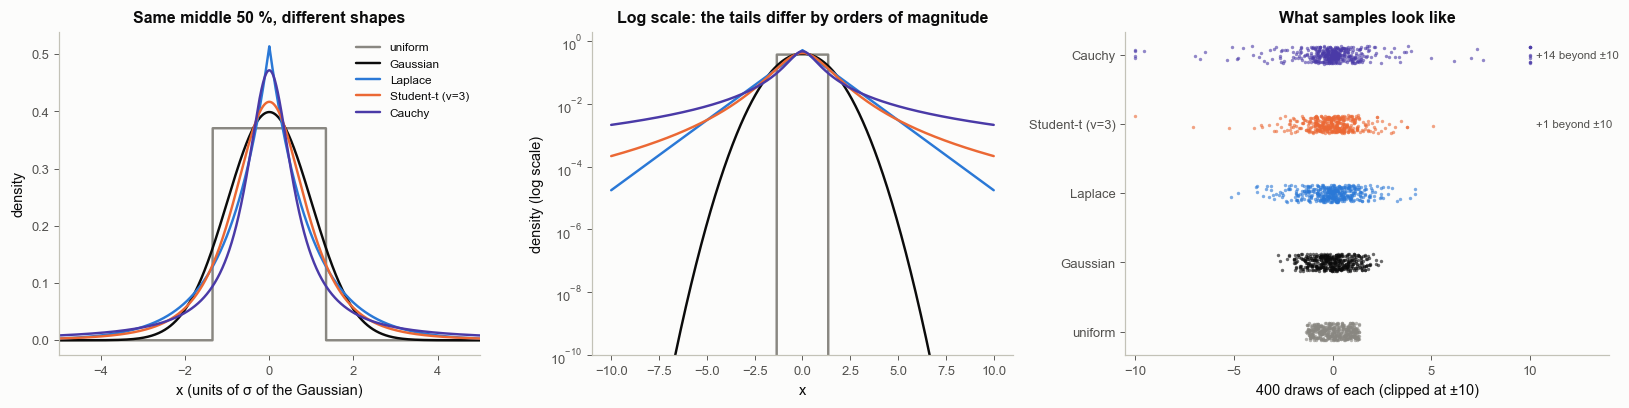

probability of |x| > 5 (Gaussian sd units), same interquartile range for all:
  uniform          0.00e+00
  Gaussian         5.73e-07
  Laplace          5.87e-03
  Student-t (ν=3)  1.09e-02
  Cauchy           8.54e-02


In [6]:
iqr_target = 2 * stats.norm.ppf(0.75) * 1.0                  # IQR of N(0, 1)
def scaled(dist_fn, iqr_unit):
    return dist_fn(iqr_target / iqr_unit)
dists = {
    "uniform": stats.uniform(loc=-iqr_target, scale=2 * iqr_target),
    "Gaussian": stats.norm(0, 1),
    "Laplace": stats.laplace(0, iqr_target / (2 * np.log(2))),
    "Student-t (ν=3)": stats.t(3, 0, iqr_target / (2 * stats.t(3).ppf(0.75))),
    "Cauchy": stats.cauchy(0, iqr_target / 2),
}
cols = {"uniform": S.MUTED, "Gaussian": S.INK, "Laplace": C1, "Student-t (ν=3)": C2, "Cauchy": C4}
for k, d in dists.items():                                  # check the common interquartile range
    assert abs((d.ppf(0.75) - d.ppf(0.25)) - iqr_target) < 1e-9, k
xg = np.linspace(-10, 10, 4001)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw=dict(width_ratios=[1, 1, 1.15]))
for k, d in dists.items():
    axs[0].plot(xg, d.pdf(xg), color=cols[k], lw=1.6, label=k)
    axs[1].semilogy(xg, np.maximum(d.pdf(xg), 1e-14), color=cols[k], lw=1.6, label=k)
axs[0].set_xlim(-5, 5); axs[0].set_title("Same middle 50 %, different shapes"); axs[0].set_xlabel("x (units of σ of the Gaussian)")
axs[0].set_ylabel("density"); axs[0].legend(fontsize=7.8)
axs[1].set_ylim(1e-10, 2); axs[1].set_title("Log scale: the tails differ by orders of magnitude")
axs[1].set_xlabel("x"); axs[1].set_ylabel("density (log scale)")
ax = axs[2]
for i, (k, d) in enumerate(dists.items()):
    smp = d.rvs(size=400, random_state=rng)
    yj = i + 0.25 * (rng.uniform(size=smp.size) - 0.5)
    inside = np.abs(smp) <= 10
    ax.scatter(np.clip(smp, -10, 10), yj, s=5, color=cols[k], alpha=0.6, lw=0)
    n_out = np.sum(~inside)
    if n_out:
        ax.text(10.3, i, f"+{n_out} beyond ±10", fontsize=7.5, va="center", color=S.INK2)
ax.set_yticks(range(len(dists))); ax.set_yticklabels(list(dists)); ax.set_xlim(-10.5, 14)
ax.set_xlabel("400 draws of each (clipped at ±10)"); ax.set_title("What samples look like")
fig.tight_layout()
bk.savefig(fig, "2-03_gallery")
plt.show()
print("probability of |x| > 5 (Gaussian sd units), same interquartile range for all:")
for k, d in dists.items():
    print(f"  {k:16s} {d.sf(5) + d.cdf(-5):.2e}")

**How to read it.** In the left panel the curves look like variations on a bump. The log scale (middle) shows what
matters for outliers: at five Gaussian standard deviations the heavy-tailed densities are many orders of
magnitude above the Gaussian (printed above). The draws (right) make it concrete: Student-t and Cauchy samples
regularly land far out.

**Worked example: one outlier, two noise models.** Nine days of a station's east coordinate scatter around the
true value, and on the tenth day a reflected signal adds a large error. Estimate the coordinate by **maximum
likelihood** (choose the value under which the observed data would have been most probable) under (a) Gaussian noise
and (b) Laplace noise.
1. Gaussian: maximise $\prod e^{-(x_i-\mu)^2/2\sigma^2}$, i.e. minimise $\sum (x_i - \mu)^2$: the answer is the mean.
2. Laplace: minimise $\sum \lvert x_i - \mu\rvert$: the answer is the median.

observed (mm): [ 1.27  0.36  0.17 -0.91  0.38 -1.89 -0.27  0.78 -1.93 25.  ]
step 1: Gaussian MLE = mean   = +2.296 mm   (grid minimum of sum of squares +2.295)
step 2: Laplace MLE  = median = +0.266 mm   (grid minimum of sum of |r|: +0.170; with an even count any value between the two middle data is a minimum)
without the outlier: mean -0.226, median +0.167


saved figures/2-03_outlier_mean_median.png


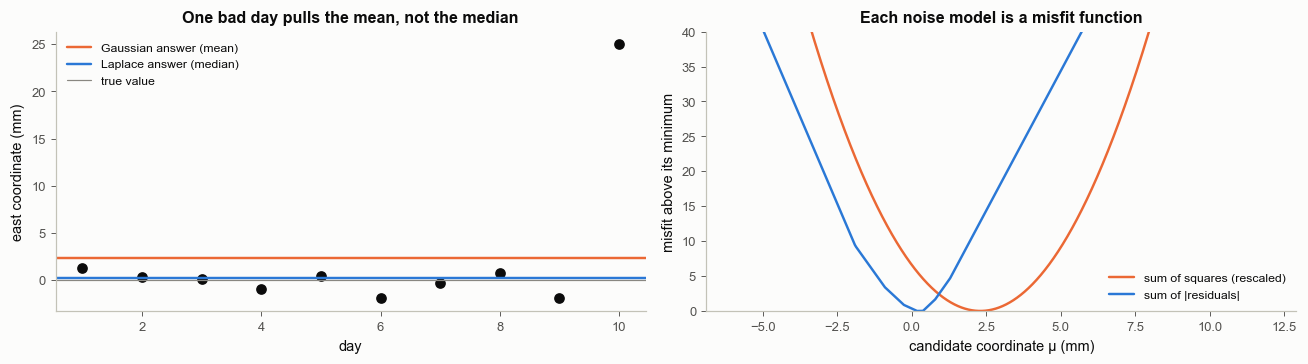

In [7]:
true_pos = 0.0
obs = true_pos + 2.0 * rng.standard_normal(9)
obs = np.append(obs, 25.0)                                   # day 10: a 25 mm multipath error
mu_grid = np.linspace(-6, 12, 3601)
sq = ((obs[None, :] - mu_grid[:, None]) ** 2).sum(1)
ab = np.abs(obs[None, :] - mu_grid[:, None]).sum(1)
print("observed (mm):", np.round(obs, 2))
print(f"step 1: Gaussian MLE = mean   = {obs.mean():+.3f} mm   (grid minimum of sum of squares {mu_grid[np.argmin(sq)]:+.3f})")
print(f"step 2: Laplace MLE  = median = {np.median(obs):+.3f} mm   (grid minimum of sum of |r|: {mu_grid[np.argmin(ab)]:+.3f}; "
      "with an even count any value between the two middle data is a minimum)")
print(f"without the outlier: mean {obs[:9].mean():+.3f}, median {np.median(obs[:9]):+.3f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
ax = axs[0]
ax.plot(np.arange(1, 11), obs, "o", color=S.INK, ms=6)
ax.axhline(obs.mean(), color=C2, lw=1.6, label="Gaussian answer (mean)")
ax.axhline(np.median(obs), color=C1, lw=1.6, label="Laplace answer (median)")
ax.axhline(true_pos, color=S.MUTED, lw=0.8, label="true value")
ax.set_xlabel("day"); ax.set_ylabel("east coordinate (mm)"); ax.legend(fontsize=8)
ax.set_title("One bad day pulls the mean, not the median")
ax = axs[1]
ax.plot(mu_grid, (sq - sq.min()) / 8.0, color=C2, lw=1.6, label="sum of squares (rescaled)")
ax.plot(mu_grid, ab - ab.min(), color=C1, lw=1.6, label="sum of |residuals|")
ax.set_xlabel("candidate coordinate μ (mm)"); ax.set_ylabel("misfit above its minimum")
ax.set_ylim(0, 40); ax.legend(fontsize=8)
ax.set_title("Each noise model is a misfit function")
fig.tight_layout()
bk.savefig(fig, "2-03_outlier_mean_median")
plt.show()

**Common misreadings.**
* "The Gaussian is the natural default." It is the right default when many small independent errors add up (2.05
  explains why); a few large errors break it.
* "L1 is just a different regulariser." As a *misfit* it is a statement that the noise has Laplace tails; as a
  *prior* (2.09) it is a statement about the parameters. Same mathematics, different claims.

**In geodesy.** Least squares is the maximum-likelihood answer only if the noise is Gaussian. Robust misfits (L1,
Student-t) are the same machinery with a heavier-tailed noise model.

## 4. Chi-square: the check that your σ is right

**In plain words.** If the noise model is right, every residual divided by its σ is one draw from a standard
Gaussian. Square those normalised residuals and add them up: the total, **χ²**, has a known distribution, and χ²
divided by the number of data should be close to 1. How close depends on how many data you have: with many data the
band around 1 is narrow. A χ²/N far below 1 does not mean a superb fit; it means the σ values are too large (or the
model fits the noise). Far above 1 means misfit or σ too small.

**Precisely.** If $z_i = r_i / \sigma_i$ are independent (knowing one tells nothing about another; 2.04) and each
$N(0, 1)$, the *standard normal*, then
$$\chi^2 = \sum_{i=1}^{N} z_i^2 \sim \chi^2_N, \qquad \mathbb E[\chi^2/N] = 1, \qquad \mathrm{sd}[\chi^2/N] = \sqrt{2/N}.$$
With $k$ parameters fitted to the same data, use $N - k$ **degrees of freedom**: each fitted parameter absorbs a
little of the noise, so the residuals come out slightly smaller than the noise itself, and the expected χ² drops by
one per parameter. Correlated noise needs $\mathbf r^\top \mathbf C_d^{-1}\mathbf r$ instead of the plain sum (section 5).

saved figures/2-03_chisquare.png


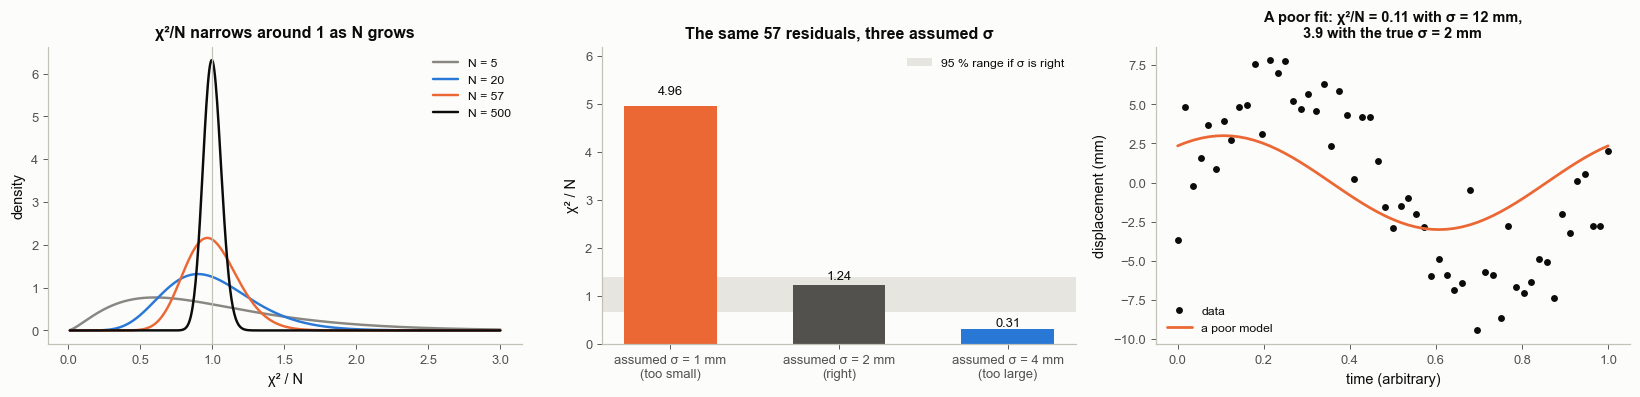

N =   5: 95 % of chi^2/N values fall between 0.17 and 2.57 when sigma is right
N =  20: 95 % of chi^2/N values fall between 0.48 and 1.71 when sigma is right
N =  57: 95 % of chi^2/N values fall between 0.67 and 1.40 when sigma is right
N = 500: 95 % of chi^2/N values fall between 0.88 and 1.13 when sigma is right


In [8]:
N57 = 57                                                     # e.g. 19 GPS sites x 3 components
true_sig = 2.0
res = true_sig * rng.standard_normal(N57)
band = stats.chi2(N57).ppf([0.025, 0.975]) / N57
fig, axs = plt.subplots(1, 3, figsize=(15, 3.7))
ax = axs[0]
q = np.linspace(0.01, 3, 600)
for n, col in zip([5, 20, 57, 500], [S.MUTED, C1, C2, S.INK]):
    ax.plot(q, stats.chi2(n).pdf(q * n) * n, color=col, lw=1.6, label=f"N = {n}")
ax.axvline(1, color=S.AXIS, lw=0.8)
ax.set_xlabel("χ² / N"); ax.set_ylabel("density"); ax.legend(fontsize=8)
ax.set_title("χ²/N narrows around 1 as N grows")
ax = axs[1]
assumed = [1.0, 2.0, 4.0]
vals = [np.sum((res / s) ** 2) / N57 for s in assumed]
ax.axhspan(band[0], band[1], color="#e6e5df", lw=0, label="95 % range if σ is right")
ax.bar(range(3), vals, color=[C2, S.INK2, C1], width=0.55)
for i, v in enumerate(vals):
    ax.text(i, v * 1.04 + 0.05, f"{v:.2f}", ha="center", fontsize=8.5)
ax.set_xticks(range(3)); ax.set_xticklabels([f"assumed σ = {s:g} mm\n({'too small' if s < true_sig else 'right' if s == true_sig else 'too large'})" for s in assumed])
ax.set_ylabel("χ² / N"); ax.legend(fontsize=8, loc="upper right")
ax.set_ylim(0, max(vals) * 1.25)
ax.set_title(f"The same {N57} residuals, three assumed σ")
ax = axs[2]
t_ = np.linspace(0, 1, N57)
signal_true = 6 * np.sin(2 * np.pi * t_)
model_bad = 3 * np.sin(2 * np.pi * t_ + 0.9)                 # a model with the wrong amplitude and phase
data_ = signal_true + true_sig * rng.standard_normal(N57)
chi_loose = np.sum(((data_ - model_bad) / 12.0) ** 2) / N57
chi_right = np.sum(((data_ - model_bad) / true_sig) ** 2) / N57
ax.plot(t_, data_, "o", color=S.INK, ms=3.5, label="data")
ax.plot(t_, model_bad, color=C2, lw=1.8, label="a poor model")
ax.set_xlabel("time (arbitrary)"); ax.set_ylabel("displacement (mm)")
ax.set_title(f"A poor fit: χ²/N = {chi_loose:.2f} with σ = 12 mm,\n{chi_right:.1f} with the true σ = 2 mm", fontsize=9.5)
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
bk.savefig(fig, "2-03_chisquare")
plt.show()
for n in [5, 20, 57, 500]:
    lo_, hi_ = stats.chi2(n).ppf([0.025, 0.975]) / n
    print(f"N = {n:3d}: 95 % of chi^2/N values fall between {lo_:.2f} and {hi_:.2f} when sigma is right")

**How to read it.** Left: with 5 data a wide range of χ²/N values is normal; with 500 the band is tight (ranges
printed above).
Middle: the *same* residuals give χ²/N far above, inside or far below the 95 % band depending only on the assumed
σ. Right: a model with clearly the wrong amplitude and phase scores χ²/N below 1 if σ is set loosely enough.

**Worked example (N = 57).** Compute χ²/N step by step for the middle panel's residuals with the right σ, and the
95 % range expected if the noise model is right.

In [9]:
z57 = res / true_sig
print(f"step 1: normalised residuals z_i = r_i / sigma; first five: {np.round(z57[:5], 3)}")
print(f"step 2: chi^2 = sum z_i^2 = {np.sum(z57 ** 2):.2f}")
print(f"step 3: chi^2 / N = {np.sum(z57 ** 2) / N57:.3f}")
print(f"step 4: 95 % range of chi^2/N for N = {N57} if sigma is right: {band[0]:.3f} to {band[1]:.3f}  (mean 1, sd {np.sqrt(2 / N57):.3f})")
print(f"assumed sigma 1, 2, 4 mm -> chi^2/N = {vals[0]:.2f}, {vals[1]:.2f}, {vals[2]:.2f}")

step 1: normalised residuals z_i = r_i / sigma; first five: [-0.263 -0.543 -0.011  0.329  0.817]
step 2: chi^2 = sum z_i^2 = 70.65
step 3: chi^2 / N = 1.240
step 4: 95 % range of chi^2/N for N = 57 if sigma is right: 0.667 to 1.399  (mean 1, sd 0.187)
assumed sigma 1, 2, 4 mm -> chi^2/N = 4.96, 1.24, 0.31


**Common misreadings.**
* "χ²/N ≪ 1 is an excellent fit." It means the stated σ is larger than the actual scatter, or the model is fitting
  the noise. Look at the residuals.
* "χ²/N ≈ 1 proves the model is right." A wrong model with the right average residual size can score 1; systematic
  patterns in the residuals are visible only in a plot.

**In practice.** This is why a fit report should quote χ²/N for each data set next to the RMS misfit, and why the
residuals should always be plotted as well: a σ that is too loose gives χ²/N far below 1 even for a fit that is
visibly bad.

## 5. Several numbers at once: the multivariate Gaussian

**In plain words.** A GPS site's east and north errors may vary *together* (a common error source pushes both). A
single bell curve per component misses that.

* The **variance** of one quantity is the average squared distance from its mean: its spread, in squared units.
* The **covariance** of two quantities ("co-variance": varying together) is the average of the *product* of their
  two deviations from their means. It is positive when they tend to rise together, negative when one tends to rise
  as the other falls, and zero when neither tells you which way the other went.
* The **correlation** is the covariance divided by both standard deviations: a number from −1 to 1 that measures
  the same thing without units.
* The **covariance matrix** collects all of this for several quantities at once: the variances on the diagonal and
  every pair's covariance off it. It is symmetric (the covariance of A with B is that of B with A). The picture in
  two dimensions is an ellipse; its tilt is the correlation.

Distance in this world is not measured in mm but in "how many standard deviations along the ellipse", the
**Mahalanobis distance**.

**Precisely.** $\mathbf x \sim N(\boldsymbol\mu, \mathbf C)$ in $n$ dimensions has density
$$p(\mathbf x) = (2\pi)^{-n/2} \lvert\mathbf C\rvert^{-1/2} \exp\!\left[-\tfrac12 (\mathbf x-\boldsymbol\mu)^\top \mathbf C^{-1}(\mathbf x-\boldsymbol\mu)\right],$$
$C_{ij} = \mathrm{Cov}(x_i, x_j) = \mathbb E[(x_i - \mu_i)(x_j - \mu_j)]$, correlation $\rho_{ij} = C_{ij}/\sqrt{C_{ii}C_{jj}}$;
$\mathbf C^{-1}$ is the matrix inverse, $\lvert\mathbf C\rvert$ the determinant and $^\top$ the transpose (2.06 explains
all three). The Mahalanobis distance $r^2 = (\mathbf x - \boldsymbol\mu)^\top \mathbf C^{-1}(\mathbf x - \boldsymbol\mu)$
follows $\chi^2_n$, so the ellipse holding probability $q$ in 2-D is $r^2 = -2\ln(1-q)$. To draw samples, factor
$\mathbf C = \mathbf L\mathbf L^\top$ with the **Cholesky factor** $\mathbf L$ (a lower-triangular "square root" of
$\mathbf C$; Cholesky factorisation, 2.06, explains it with pictures; the worked example below computes one by hand)
and set $\mathbf x = \boldsymbol\mu + \mathbf L\mathbf z$ with $\mathbf z \sim N(0, \mathbf I)$, independent
standard normals.

**Which matrices can be covariances.** Take any weighted combination of the quantities, $y = \mathbf a^\top\mathbf x$.
Its variance is $\mathbf a^\top\mathbf C\mathbf a$, and a variance cannot be negative. So a covariance matrix must
satisfy $\mathbf a^\top\mathbf C\mathbf a \ge 0$ for every $\mathbf a$: it is **positive semi-definite**. An equivalent test
uses the **eigen-decomposition** $\mathbf C = \mathbf V\boldsymbol\Lambda\mathbf V^\top$: the eigenvectors (columns of
$\mathbf V$) are the directions of the ellipse's axes, and the eigenvalues (the diagonal of $\boldsymbol\Lambda$) are the
variances along those axes (the worked example below draws them; 2.06 gives the general picture). Positive
semi-definite means all eigenvalues are $\ge 0$. It is **positive definite** (all eigenvalues $> 0$, and then $\mathbf C^{-1}$
and the Cholesky factor exist) when no combination of the quantities is exactly fixed. It is only semi-definite,
*singular*, when some combination has zero spread:
* two quantities that are perfectly correlated (one is a fixed multiple of the other);
* a constraint, such as proportions that must add up to one (their sum never varies);
* a covariance estimated from fewer samples (ensemble members) than there are quantities (2.24);
* a smoothing prior that leaves some pattern completely free, a *null space* (2.09, 2.12).

A matrix written down by hand, for example by choosing correlations pair by pair, can have a negative eigenvalue.
Then it is not a covariance of anything: some combination would have a negative variance. Round-off error in a
computer can also push a nearly singular covariance slightly negative, which is why codes add a tiny "jitter" to the
diagonal and check that a Cholesky factorisation succeeds (it exists only for positive-definite matrices). A worked
example below checks all three cases.

saved figures/2-03_multivariate.png


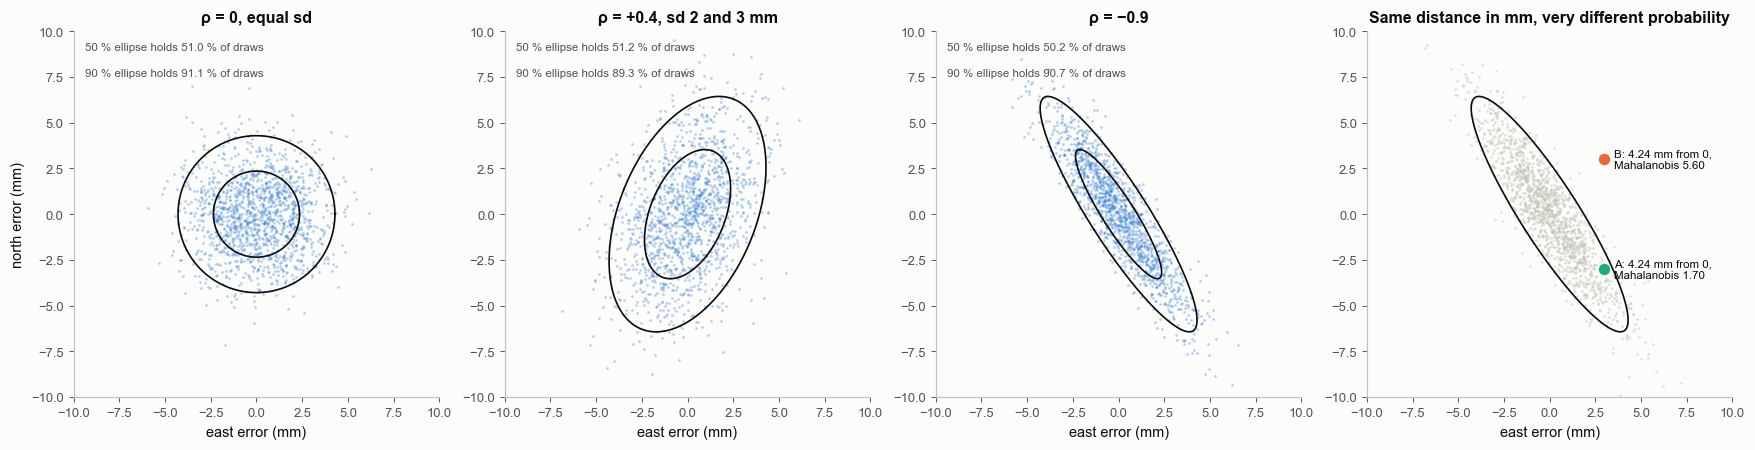

In [10]:
covs = [("ρ = 0, equal sd", np.array([[4.0, 0.0], [0.0, 4.0]])),
        ("ρ = +0.4, sd 2 and 3 mm", np.array([[4.0, 2.4], [2.4, 9.0]])),
        ("ρ = −0.9", np.array([[4.0, -5.4], [-5.4, 9.0]]))]
fig, axs = plt.subplots(1, 4, figsize=(16, 3.9))
for ax, (lab, C) in zip(axs[:3], covs):
    Lc = np.linalg.cholesky(C)
    smp = (Lc @ rng.standard_normal((2, 1500))).T
    ax.scatter(smp[:, 0], smp[:, 1], s=3, color=C1, alpha=0.35, lw=0)
    for qq in (0.5, 0.9):
        BP.ellipse(ax, np.zeros(2), C, nsig=np.sqrt(-2 * np.log(1 - qq)), color=S.INK, lw=1.1)
        inside = np.mean(np.einsum("ij,jk,ik->i", smp, np.linalg.inv(C), smp) < -2 * np.log(1 - qq))
        ax.text(0.03, 0.97 - 0.07 * (qq == 0.9), f"{int(100 * qq)} % ellipse holds {100 * inside:.1f} % of draws",
                transform=ax.transAxes, fontsize=7.5, va="top", color=S.INK2)
    ax.set_xlim(-10, 10); ax.set_ylim(-10, 10); ax.set_aspect("equal")
    ax.set_xlabel("east error (mm)"); ax.set_title(lab)
axs[0].set_ylabel("north error (mm)")
ax = axs[3]
C = covs[2][1]
smp = (np.linalg.cholesky(C) @ rng.standard_normal((2, 1500))).T
ax.scatter(smp[:, 0], smp[:, 1], s=3, color="#c3c2b7", alpha=0.5, lw=0)
BP.ellipse(ax, np.zeros(2), C, nsig=np.sqrt(-2 * np.log(0.1)), color=S.INK, lw=1.1)
pA, pB = np.array([3.0, -3.0]), np.array([3.0, 3.0])
for p_, name, col in [(pA, "A", C3), (pB, "B", C2)]:
    md = np.sqrt(p_ @ np.linalg.inv(C) @ p_)
    ax.plot(*p_, "o", color=col, ms=9, mec=S.SURFACE, mew=1.5)
    ax.text(p_[0] + 0.5, p_[1], f"{name}: {np.linalg.norm(p_):.2f} mm from 0,\nMahalanobis {md:.2f}", fontsize=7.5, va="center")
ax.set_xlim(-10, 10); ax.set_ylim(-10, 10); ax.set_aspect("equal"); ax.set_xlabel("east error (mm)")
ax.set_title("Same distance in mm, very different probability")
fig.tight_layout()
bk.savefig(fig, "2-03_multivariate")
plt.show()

**How to read it.** The 50 % and 90 % ellipses hold those shares of the draws (counted in each panel). In the last
panel A and B are equally far from the centre in millimetres, but A lies along the ellipse and B across it: B is a
far more surprising error.

**Worked example: sampling by hand with the Cholesky factor.** Take sd 2 mm (east) and 3 mm (north) with
correlation 0.4, so $\mathbf C = \begin{pmatrix}4 & 2.4\\ 2.4 & 9\end{pmatrix}$ mm².
1. $L_{11} = \sqrt{C_{11}}$, $L_{21} = C_{21}/L_{11}$, $L_{22} = \sqrt{C_{22} - L_{21}^2}$.
2. Draw two standard normals $z_1, z_2$ and form $x_1 = L_{11}z_1$, $x_2 = L_{21}z_1 + L_{22}z_2$.
3. Check: numpy's Cholesky, and the covariance of many such draws.

In [11]:
C = np.array([[4.0, 2.4], [2.4, 9.0]])
L11 = np.sqrt(C[0, 0]); L21 = C[1, 0] / L11; L22 = np.sqrt(C[1, 1] - L21 ** 2)
print(f"step 1: L11 = sqrt(4) = {L11:.4f},  L21 = 2.4 / L11 = {L21:.4f},  L22 = sqrt(9 - L21^2) = {L22:.4f}")
z2 = rng.standard_normal(2)
print(f"step 2: z = {np.round(z2, 4)} -> x1 = {L11 * z2[0]:+.4f} mm, x2 = {L21 * z2[0] + L22 * z2[1]:+.4f} mm")
print("step 3: numpy cholesky:\n", np.round(np.linalg.cholesky(C), 4))
Xm = (np.linalg.cholesky(C) @ rng.standard_normal((2, 200_000))).T
print("        covariance of 200,000 draws:\n", np.round(np.cov(Xm.T), 3), "\n        correlation:", round(np.corrcoef(Xm.T)[0, 1], 4))

step 1: L11 = sqrt(4) = 2.0000,  L21 = 2.4 / L11 = 1.2000,  L22 = sqrt(9 - L21^2) = 2.7495
step 2: z = [-0.6574 -0.436 ] -> x1 = -1.3149 mm, x2 = -1.9877 mm
step 3: numpy cholesky:
 [[2.     0.    ]
 [1.2    2.7495]]
        covariance of 200,000 draws:
 [[3.998 2.386]
 [2.386 8.947]] 
        correlation: 0.3989


**Worked example: valid, singular and impossible covariances.** (1) The matrix above. (2) The covariance of three
quantities estimated from only two samples. (3) A hand-built 3 × 3 "correlation matrix" with correlations +0.9
(A with B), +0.9 (A with C) and −0.9 (B with C): if A follows B closely and C closely, B and C cannot be opposite.

(1) the 2 x 2 example above                eigenvalues [3.034 9.966]                Cholesky succeeds
(2) estimated from 2 samples of 3 quantities eigenvalues [-0.     0.     3.782]       Cholesky FAILS
(3) hand-built correlations +0.9, +0.9, -0.9 eigenvalues [-0.8  1.9  1.9]             Cholesky FAILS
    the combination a = [-0.577  0.577  0.577] would have 'variance' a^T C a = -0.800 < 0: impossible


saved figures/2-03_eigen_and_validity.png


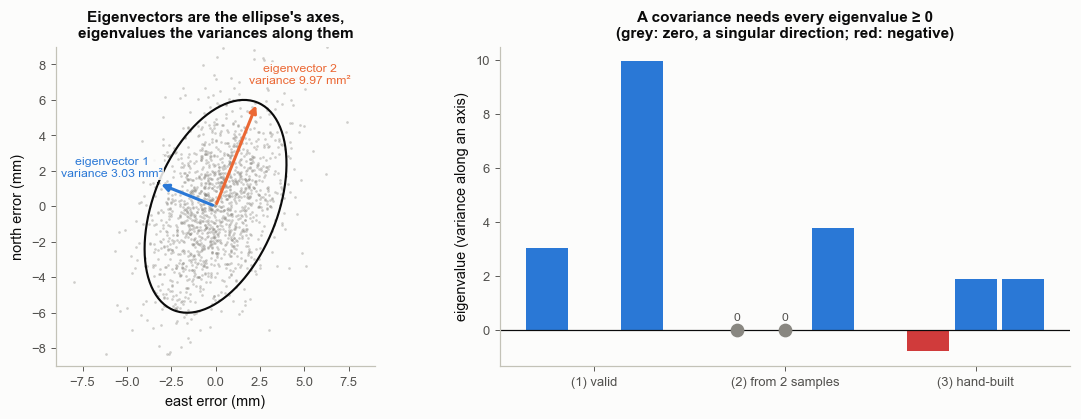

In [12]:
def describe(name, M):
    ev = np.linalg.eigvalsh(M)
    try:
        np.linalg.cholesky(M); chol = "succeeds"
    except np.linalg.LinAlgError:
        chol = "FAILS"
    print(f"{name:42s} eigenvalues {np.array2string(ev, precision=3, suppress_small=True):28s} Cholesky {chol}")


describe("(1) the 2 x 2 example above", C)
two = rng.standard_normal((2, 3))                                # two samples of three quantities
describe("(2) estimated from 2 samples of 3 quantities", np.cov(two.T))
bad = np.array([[1.0, 0.9, 0.9], [0.9, 1.0, -0.9], [0.9, -0.9, 1.0]])
describe("(3) hand-built correlations +0.9, +0.9, -0.9", bad)
a = np.linalg.eigh(bad)[1][:, 0]
print(f"    the combination a = {np.round(a, 3)} would have 'variance' a^T C a = {a @ bad @ a:.3f} < 0: impossible")

lam, V = np.linalg.eigh(C)
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.9), gridspec_kw=dict(width_ratios=[1, 1.15]))
ax = axs[0]
draws = (np.linalg.cholesky(C) @ rng.standard_normal((2, 1500))).T
ax.scatter(*draws.T, s=3, color=S.MUTED, alpha=0.4, lw=0, rasterized=True)
tt = np.linspace(0, 2 * np.pi, 200)
ell = V @ (np.sqrt(lam)[:, None] * np.vstack([np.cos(tt), np.sin(tt)])) * 2
ax.plot(*ell, color=S.INK, lw=1.4, label="2-sd ellipse")
for k, c in zip(range(2), (S.BLUE, S.ORANGE)):
    ax.annotate("", xy=2 * np.sqrt(lam[k]) * V[:, k], xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2))
    ax.text(*(2 * np.sqrt(lam[k]) * V[:, k] + np.array([[-2.6, 0.9], [2.4, 1.6]])[k]), f"eigenvector {k + 1}\nvariance {lam[k]:.2f} mm²",
            color=c, fontsize=8, ha="center", va="center", bbox=dict(fc=S.SURFACE, ec="none", alpha=0.85, pad=1))
ax.set_aspect("equal"); ax.set_xlim(-9, 9); ax.set_ylim(-9, 9)
ax.set_xlabel("east error (mm)"); ax.set_ylabel("north error (mm)")
ax.set_title("Eigenvectors are the ellipse's axes,\neigenvalues the variances along them", fontsize=10)
ax = axs[1]
cases = [("(1) valid", np.linalg.eigvalsh(C)), ("(2) from 2 samples", np.linalg.eigvalsh(np.cov(two.T))),
         ("(3) hand-built", np.linalg.eigvalsh(bad))]
for j, (nm, ev) in enumerate(cases):
    xs = j + np.linspace(-0.25, 0.25, len(ev))
    ax.bar(xs, ev, width=0.22, color=[S.BAD if e < -1e-10 else S.BLUE for e in ev])
    for x_, e in zip(xs, ev):
        if abs(e) < 1e-10:                                       # a zero eigenvalue: mark it, a bar would be invisible
            ax.plot(x_, 0, "o", color=S.MUTED, ms=8, zorder=3)
            ax.text(x_, 0.35, "0", ha="center", fontsize=8, color=S.INK2)
ax.axhline(0, color=S.INK, lw=0.8)
ax.set_xticks(range(3)); ax.set_xticklabels([c[0] for c in cases])
ax.set_ylabel("eigenvalue (variance along an axis)")
ax.set_title("A covariance needs every eigenvalue ≥ 0\n(grey: zero, a singular direction; red: negative)", fontsize=10)
fig.tight_layout()
bk.savefig(fig, "2-03_eigen_and_validity")
plt.show()

**How to read it.** Left: the covariance matrix of the worked example as an ellipse; its two eigenvectors point
along the axes, and the eigenvalues printed on them are the variances in those directions. Right: (1) both
eigenvalues are positive, a proper positive-definite covariance. (2) Two samples of three quantities: two of the three
eigenvalues are zero up to round-off, because two samples (minus their mean) leave only one direction of spread, so the
estimated covariance is singular and its Cholesky factorisation may fail or be numerically meaningless. (3) One
eigenvalue is negative: no set of three quantities can have these correlations.

**Common misreadings.**
* "Two uncorrelated sd values describe the uncertainty." Only if the off-diagonal covariance is zero; otherwise the
  ellipse is tilted and the sd values alone hide the trade-off (notebook 2.02's trade-off ridge).
* "Distance in mm measures how unusual a point is." Mahalanobis distance does; 2.07 uses exactly this as the misfit.

**In geodesy.** $\mathbf C_d$ for GPS is a covariance matrix of exactly this kind (east, north, up with different σ
and, from the processing, correlations). The posterior of slip on neighbouring patches is another one.

## 6. Positive quantities: the log-normal

**In plain words.** Viscosity (how strongly rock resists slow flow, in Pa s), rigidity (how stiff it is), a creep
rate (how fast a fault slides without earthquakes): these cannot be negative, and their uncertainty is usually
*multiplicative* ("within a factor of three") rather than additive ("±10¹⁸ Pa s"). The natural description is
then a Gaussian for the *logarithm*. The quantity itself has a skewed, **log-normal** distribution, and its mean is
larger than its median.

**Precisely.** If $\ln X \sim N(\mu, s^2)$ then $X$ is log-normal with median $e^{\mu}$, mean $e^{\mu + s^2/2}$ and
mode $e^{\mu - s^2}$. With base-10 logs, $\log_{10} X \sim N(\mu_{10}, s_{10}^2)$ means a 95 % range of
$10^{\mu_{10} \pm 1.96\, s_{10}}$, a multiplicative factor around the median.

saved figures/2-03_lognormal.png


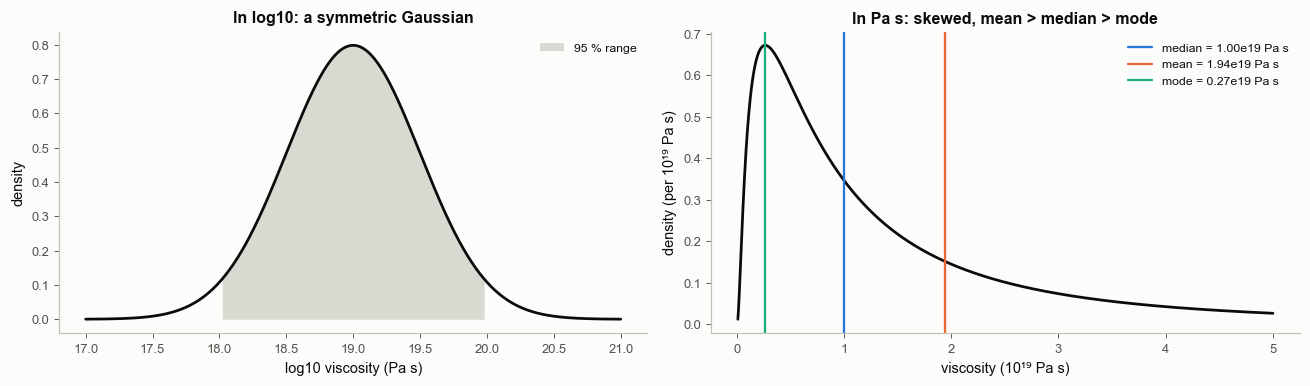

In [13]:
mu10, s10 = 19.0, 0.5                                      # log10 viscosity (Pa s): 1e19, give or take a factor of ~3
lv = np.linspace(17, 21, 800)
eta = 10 ** lv
pdf_log = stats.norm(mu10, s10).pdf(lv)
ln_mu, ln_s = mu10 * np.log(10), s10 * np.log(10)
lnorm = stats.lognorm(s=ln_s, scale=np.exp(ln_mu))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axs[0]
ax.plot(lv, pdf_log, color=S.INK, lw=1.8)
lo, hi = stats.norm(mu10, s10).ppf([0.025, 0.975])
ax.fill_between(lv, pdf_log, where=(lv >= lo) & (lv <= hi), color="#d9d8d1", lw=0, label="95 % range")
ax.set_xlabel("log10 viscosity (Pa s)"); ax.set_ylabel("density"); ax.legend(fontsize=8)
ax.set_title("In log10: a symmetric Gaussian")
ax = axs[1]
e = np.linspace(1e17, 5e19, 2000)
ax.plot(e / 1e19, lnorm.pdf(e) * 1e19, color=S.INK, lw=1.8)
for val, lab, col in [(lnorm.median(), "median", C1), (lnorm.mean(), "mean", C2), (np.exp(ln_mu - ln_s ** 2), "mode", C3)]:
    ax.axvline(val / 1e19, color=col, lw=1.5, label=f"{lab} = {val / 1e19:.2f}e19 Pa s")
ax.set_xlabel("viscosity (10¹⁹ Pa s)"); ax.set_ylabel("density (per 10¹⁹ Pa s)"); ax.legend(fontsize=8)
ax.set_title("In Pa s: skewed, mean > median > mode")
fig.tight_layout()
bk.savefig(fig, "2-03_lognormal")
plt.show()

**Worked example.** $\log_{10}\eta \sim N(19, 0.5^2)$.
1. median $= 10^{19}$ Pa s;
2. 95 % range $= 10^{19 \pm 1.96 \times 0.5}$, i.e. the median times or divided by $10^{0.98}$;
3. mean $= e^{\mu + s^2/2}$ with natural-log parameters $\mu = 19\ln 10$, $s = 0.5\ln 10$;
4. check by drawing 100,000 values.

In [14]:
draws_eta = 10 ** (mu10 + s10 * rng.standard_normal(100_000))
print(f"step 1: median = 10^{mu10:.0f} = {10 ** mu10:.3e} Pa s")
print(f"step 2: 95 % range = {10 ** lo:.3e} to {10 ** hi:.3e} Pa s  (a factor of {10 ** (1.96 * s10):.2f} either way)")
print(f"step 3: mean = exp(mu + s^2/2) = {np.exp(ln_mu + ln_s ** 2 / 2):.3e} Pa s")
print(f"step 4: from 100,000 draws: median {np.median(draws_eta):.3e}, mean {draws_eta.mean():.3e}")

step 1: median = 10^19 = 1.000e+19 Pa s
step 2: 95 % range = 1.047e+18 to 9.550e+19 Pa s  (a factor of 9.55 either way)
step 3: mean = exp(mu + s^2/2) = 1.940e+19 Pa s
step 4: from 100,000 draws: median 1.000e+19, mean 1.936e+19


**Common misreadings.**
* "Average the viscosities of several models." Averaging in Pa s is dominated by the stiffest model; averaging
  $\log_{10}\eta$ is usually what is meant.
* "A Gaussian prior on viscosity with a large sd is uninformative." It puts probability on negative viscosity and
  is far from flat in $\log\eta$.

**In practice.** Positive quantities that span orders of magnitude (viscosity, a reference slip rate $v_0$, a noise
scale) are usually inverted for in log units, or given priors that live on positive numbers only (log-normal,
half-normal, half-Cauchy): the same reasoning. 2.11 compares these priors.

## Summary

| distribution | arises when | tails | as a misfit (noise model) |
|---|---|---|---|
| Gaussian | many small independent errors add up (2.05) | thinnest | least squares (L2) |
| Laplace | occasional large errors | exponential | sum of absolute residuals (L1) |
| Student-t | outliers of unknown size | power law | robust, down-weights outliers |
| Cauchy | ratio of noisy quantities, extreme outliers | no mean | very robust; averages never settle (2.05) |
| uniform | hard bounds, nothing else known | none | box constraint |
| log-normal | positive quantities known within a factor | one long tail | least squares in log units |
| χ² | sum of squared normalised residuals | – | the fit check χ²/N ≈ 1 |

Next: [**2.04 · Joint, marginal and conditional probability; Bayes' rule**](2-04_conditional_probability.ipynb).